# PR9: Clustering Techniques (CO4)


In [1]:
print("Developer name = \u0905\u092F\u093E\u0928 \u0916\u093E\u0928")
print("Evaluator : \u0935\u0948\u0936\u093e\u0932\u0940 \u0907\u0902\u0917\u0933\u0947")
print("Evaluator : \u0936\u094d\u0935\u0947\u0924\u093e \u0935\u093e\u0928\u0916\u0947\u0921\u0947")

Developer name = अयान खान
Evaluator : वैशाली इंगळे
Evaluator : श्वेता वानखेडे


## 1. Import Required Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
os.environ["OMP_NUM_THREADS"] = "1"
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage, is_valid_linkage
from matplotlib.patches import Ellipse
from matplotlib.lines import Line2D
from IPython.display import display


In [3]:
RANDOM_STATE = 42


## 2. Load the Iris Dataset

In [4]:
import os

# Keep Iris.csv in the same folder as this notebook, or place it in a data/ folder.
possible_paths = [
    "Iris.csv",
    os.path.join("data", "Iris.csv"),
    r"D:\\AIML\\pr 9\\Iris.csv"
]
dataset_path = next((path for path in possible_paths if os.path.isfile(path)), None)

if dataset_path is None:
    raise FileNotFoundError(
        "Iris.csv not found. Put Iris.csv beside this notebook or inside a data/ folder."
    )

df = pd.read_csv(dataset_path)
print(f"Dataset loaded successfully from: {dataset_path}")
print("Shape of dataset:", df.shape)
display(df.head())


Dataset loaded successfully from: Iris.csv
Shape of dataset: (150, 6)


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


## 3. Explore the Dataset

In [5]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include='all'))

Column names:
['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 9.1 KB

Statistical summary:


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
count,150.000000,150.000000,150.000000,150.000000,150.000000,150
unique,NaN,NaN,NaN,NaN,NaN,3
top,NaN,NaN,NaN,NaN,NaN,Iris-setosa
freq,NaN,NaN,NaN,NaN,NaN,50
mean,75.500000,5.843333,3.054000,3.758667,1.198667,NaN
std,43.445368,0.828066,0.433594,1.764420,0.763161,NaN
min,1.000000,4.300000,2.000000,1.000000,0.100000,NaN
25%,38.250000,5.100000,2.800000,1.600000,0.300000,NaN
50%,75.500000,5.800000,3.000000,4.350000,1.300000,NaN
75%,112.750000,6.400000,3.300000,5.100000,1.800000,NaN


## 4. Data Preprocessing

In [6]:
feature_columns = [
    'SepalLengthCm',
    'SepalWidthCm',
    'PetalLengthCm',
    'PetalWidthCm'
]

missing_columns = [col for col in feature_columns + ['Species'] if col not in df.columns]
if missing_columns:
    raise ValueError(f'Missing required columns in Iris.csv: {missing_columns}')

X = df[feature_columns].copy()
if X.isnull().any().any():
    raise ValueError('Feature columns contain missing values. Clean the dataset before clustering.')

print("Features used for clustering:")
display(X.head())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled feature matrix shape:", X_scaled.shape)

Features used for clustering:


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


Scaled feature matrix shape: (150, 4)


# Part A: K-Means Clustering
## 5. Find Optimal Number of Clusters Using the Elbow Method

In [7]:
inertia_values = []
k_values = range(1, 11)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    kmeans.fit(X_scaled)
    inertia_values.append(kmeans.inertia_)

print("Inertia values:")
for k, inertia in zip(k_values, inertia_values):
    print(f"K = {k}: Inertia = {inertia:.2f}")

Inertia values:
K = 1: Inertia = 600.00
K = 2: Inertia = 223.73
K = 3: Inertia = 140.97
K = 4: Inertia = 114.62
K = 5: Inertia = 91.30
K = 6: Inertia = 81.76
K = 7: Inertia = 71.32
K = 8: Inertia = 62.65
K = 9: Inertia = 55.26
K = 10: Inertia = 50.62


## 6. Elbow Plot

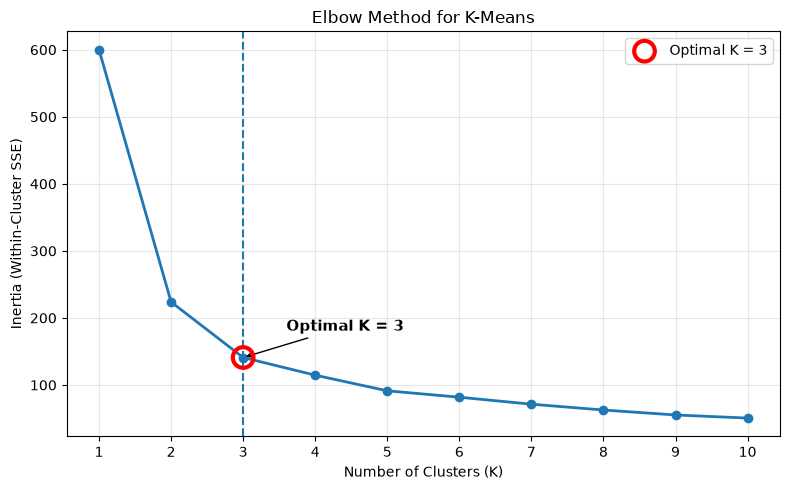

Selected number of clusters: 3


In [8]:
elbow_k = 3
elbow_inertia = inertia_values[elbow_k - 1]
plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia_values, marker='o', linewidth=2)
plt.scatter(elbow_k, elbow_inertia, s=220, facecolors='none', edgecolors='red',
            linewidths=3, zorder=5, label=f'Optimal K = {elbow_k}')
plt.axvline(elbow_k, color='tab:blue', linestyle='--')
plt.annotate(f'Optimal K = {elbow_k}', xy=(elbow_k, elbow_inertia),
             xytext=(elbow_k + 0.6, elbow_inertia + 40),
             arrowprops={'arrowstyle': '->'}, fontsize=11, fontweight='bold')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia (Within-Cluster SSE)')
plt.title('Elbow Method for K-Means')
plt.xticks(k_values)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()
print('Selected number of clusters:', elbow_k)


## 7. Apply K-Means with Optimal K

In [9]:
def add_cluster_labels(data, column):
    counts = pd.crosstab(data[column], data['Species'])
    labels, rows = {}, []
    for cluster_id, row in counts.iterrows():
        winners = row[row == row.max()].index
        names = ' / '.join(name.replace('Iris-', '').title() for name in winners)
        description = 'mostly ' if len(winners) == 1 else 'tie: '
        labels[cluster_id] = f'Cluster {cluster_id} ({description}{names})'
        rows.append([cluster_id, labels[cluster_id], row.sum(),
                     round(100 * row.max() / row.sum(), 1)])
    data[column + '_Label'] = data[column].map(labels)
    display(pd.DataFrame(rows, columns=['Cluster ID', 'Legend label', 'Flowers',
                                       'Largest species share (%)']))
    return labels

In [10]:
SPECIES_COLORS = {'Iris-setosa': '#2ca02c', 'Iris-versicolor': '#ff7f0e',
                  'Iris-virginica': '#9467bd'}

def cluster_colors(data, column):
    colors = {}
    for cluster_id, row in pd.crosstab(data[column], data['Species']).iterrows():
        winners = row[row == row.max()].index
        colors[cluster_id] = SPECIES_COLORS[winners[0]] if len(winners) == 1 else '#777777'
    return colors

def circle_groups(ax, data, column, colors):
    for group, points in data.groupby(column):
        values = points[['PetalLengthCm', 'PetalWidthCm']].to_numpy()
        low, high = values.min(axis=0), values.max(axis=0)
        width, height = np.maximum(high - low, [0.12, 0.08]) * np.sqrt(2) * 1.05
        ax.add_patch(Ellipse((low + high) / 2, width, height, fill=False,
                            edgecolor=colors[group], linewidth=2.2, linestyle='--'))
    ax.autoscale_view()

def plot_cluster_scatter(ax, column, title, centers=None):
    actual = column == 'Species'
    colors = SPECIES_COLORS if actual else cluster_colors(df, column)
    for group, points in df.groupby(column):
        label = group.replace('Iris-', '').title() if actual else points[column + '_Label'].iloc[0]
        ax.scatter(points['PetalLengthCm'], points['PetalWidthCm'],
                   color=colors[group], s=65, alpha=0.85, label=label)
    circle_groups(ax, df, column, colors)
    if centers is not None:
        ax.scatter(centers[:, 2], centers[:, 3], marker='X', s=220,
                   color='black', label='Centroids', zorder=4)
    ax.set(title=title, xlabel='Petal Length (cm)', ylabel='Petal Width (cm)')
    ax.legend(title='Actual Species' if actual else 'Cluster (majority species)',
              fontsize=8, loc='upper left')
    ax.grid(alpha=0.25)

def plot_actual_scatter(ax):
    plot_cluster_scatter(ax, 'Species', 'Actual Iris Species')

def plot_colored_dendrogram(ax, matrix, title, column=None, ylabel='Ward distance'):
    column = column or 'Species'
    actual = column == 'Species'
    colors = SPECIES_COLORS if actual else cluster_colors(df, column)
    # A branch gets a color only when all its flowers belong to one group.
    groups = {i: {value} for i, value in enumerate(df[column])}
    branch_colors = {}
    for i, row in enumerate(matrix):
        node = len(df) + i
        groups[node] = groups[int(row[0])] | groups[int(row[1])]
        branch_colors[node] = colors[next(iter(groups[node]))] if len(groups[node]) == 1 else '#777777'
    tree = dendrogram(matrix, ax=ax, no_labels=True,
                      link_color_func=lambda node: branch_colors[node])
    # Bottom marks show actual species in the tree's leaf order.
    leaf_colors = df.iloc[tree['leaves']]['Species'].map(SPECIES_COLORS)
    ax.scatter(np.arange(len(df)) * 10 + 5, np.full(len(df), -0.035),
               c=leaf_colors, marker='|', s=35,
               transform=ax.get_xaxis_transform(), clip_on=False)
    handles = []
    for group, color in colors.items():
        label = group.replace('Iris-', '').title() if actual else df.loc[df[column] == group, column + '_Label'].iloc[0]
        handles.append(Line2D([0], [0], color=color, lw=2, label=label))
    handles.append(Line2D([0], [0], color='#777777', lw=2, label='Mixed / connecting branches'))
    ax.legend(handles=handles, title='Branch color', fontsize=7, loc='upper right')
    ax.set(title=title, xlabel='Flowers (bottom marks = actual species)', ylabel=ylabel)
    ax.grid(axis='y', alpha=0.25)
    return tree

### 7.1 Train-Test Split


In [11]:
from sklearn.model_selection import train_test_split

all_indices = np.arange(len(X))
train_indices, test_indices = train_test_split(
    all_indices, test_size=0.20, random_state=RANDOM_STATE)
X_train = X.iloc[train_indices].copy()
X_test = X.iloc[test_indices].copy()

print(f'Training samples: {len(train_indices)} ({len(train_indices)/len(X):.0%})')
print(f'Testing samples: {len(test_indices)} ({len(test_indices)/len(X):.0%})')


Training samples: 120 (80%)
Testing samples: 30 (20%)


### 7.2 Standardize Training and Testing Data


In [12]:
# Separate scaler for K-Means; fit on training data only.
kmeans_scaler = StandardScaler()
X_train_scaled = kmeans_scaler.fit_transform(X_train)
X_test_scaled = kmeans_scaler.transform(X_test)
kmeans_X_scaled = kmeans_scaler.transform(X)
kmeans_scaled_df = pd.DataFrame(kmeans_X_scaled, columns=X.columns, index=X.index)

print('Standardized training data:')
display(pd.DataFrame(X_train_scaled, columns=X.columns, index=X_train.index).head())
print('Standardized testing data:')
display(pd.DataFrame(X_test_scaled, columns=X.columns, index=X_test.index).head())


Standardized training data:


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
22,-1.473937,1.220379,-1.563987,-1.309484
15,-0.133071,3.020017,-1.277280,-1.042922
65,1.085898,0.095606,0.385621,0.289886
11,-1.230143,0.770470,-1.219939,-1.309484
42,-1.717731,0.320560,-1.391963,-1.309484


Standardized testing data:


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
73,0.354517,-0.579258,0.557645,0.023324
18,-0.133071,1.670289,-1.162597,-1.176203
118,2.304867,-1.029168,1.819157,1.489413
78,0.232620,-0.354304,0.442962,0.423166
76,1.207795,-0.579258,0.614987,0.289886


### 7.3 Train K-Means and Predict Clusters


In [13]:
optimal_k = 3
kmeans = KMeans(n_clusters=optimal_k, random_state=RANDOM_STATE,
                n_init=10, algorithm='lloyd')
kmeans.fit(X_train_scaled)

kmeans_labels = kmeans.predict(kmeans_X_scaled)
train_kmeans_labels = kmeans.predict(X_train_scaled)
test_kmeans_labels = kmeans.predict(X_test_scaled)
kmeans_clusters = kmeans_labels
df['KMeans_Cluster'] = kmeans_labels

kmeans_result = X.copy()
kmeans_result['Cluster'] = kmeans_labels
kmeans_result['Set'] = 'Test'
kmeans_result.loc[X.index[train_indices], 'Set'] = 'Train'
kmeans_cluster_labels = add_cluster_labels(df, 'KMeans_Cluster')

print('K-Means fitted on training data only.')
print('Training cluster sizes:')
print(pd.Series(train_kmeans_labels).value_counts().sort_index())
print('\nTesting cluster sizes:')
print(pd.Series(test_kmeans_labels).value_counts().sort_index())
print('\nAll-data cluster sizes (train + test):')
print(kmeans_result['Cluster'].value_counts().sort_index())


,Cluster ID,Legend label,Flowers,Largest species share (%)
0,0,Cluster 0 (mostly Virginica),45,75.6
1,1,Cluster 1 (mostly Setosa),50,100.0
2,2,Cluster 2 (mostly Versicolor),55,70.9


K-Means fitted on training data only.
Training cluster sizes:
0    33
1    40
2    47
Name: count, dtype: int64

Testing cluster sizes:
0    12
1    10
2     8
Name: count, dtype: int64

All-data cluster sizes (train + test):
Cluster
0    45
1    50
2    55
Name: count, dtype: int64


## 8. Visualize K-Means Clusters

In [14]:
def plot_feature_scatter(ax, column, pair, title, centers=None, train_test=False):
    actual = column == 'Species'
    colors = SPECIES_COLORS if actual else cluster_colors(df, column)
    for group, points in df.groupby(column):
        label = group.replace('Iris-', '').title() if actual else points[column + '_Label'].iloc[0]
        if train_test:
            for split, marker in [('Train', 'o'), ('Test', 'x')]:
                subset = points[kmeans_result.loc[points.index, 'Set'] == split]
                ax.scatter(subset[pair[0]], subset[pair[1]], color=colors[group],
                           marker=marker, s=65, alpha=0.85, label=label if split == 'Train' else None)
        else:
            ax.scatter(points[pair[0]], points[pair[1]], color=colors[group],
                       s=65, alpha=0.85, label=label)
        # Same enclosing circles/ovals for either feature pair.
        values = points[pair].to_numpy()
        low, high = values.min(axis=0), values.max(axis=0)
        width, height = np.maximum(high - low, [0.12, 0.08]) * np.sqrt(2) * 1.05
        ax.add_patch(Ellipse((low + high) / 2, width, height, fill=False,
                            edgecolor=colors[group], linewidth=2.2, linestyle='--'))
    if centers is not None:
        positions = [feature_columns.index(name) for name in pair]
        ax.scatter(centers[:, positions[0]], centers[:, positions[1]], color='black',
                   marker='X', s=220, label='Centroids', zorder=4)
    if train_test:
        ax.scatter([], [], color='black', marker='o', label='Train sample')
        ax.scatter([], [], color='black', marker='x', label='Test sample')
    ax.set(title=title, xlabel=pair[0], ylabel=pair[1])
    ax.legend(title='Actual Species' if actual else 'Cluster (majority species)', fontsize=8)
    ax.grid(alpha=0.25)
    ax.autoscale_view()

def compare_clusters(column, pair, method, centers=None, train_test=False):
    fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True, sharey=True)
    plane = 'Sepal' if pair[0].startswith('Sepal') else 'Petal'
    plot_feature_scatter(axes[0], 'Species', pair, f'Actual Species - {plane}',
                         train_test=train_test)
    plot_feature_scatter(axes[1], column, pair, f'{method} Clusters - {plane}',
                         centers=centers, train_test=train_test)
    plt.tight_layout()
    plt.show()

petal_pair = ['PetalLengthCm', 'PetalWidthCm']
sepal_pair = ['SepalLengthCm', 'SepalWidthCm']


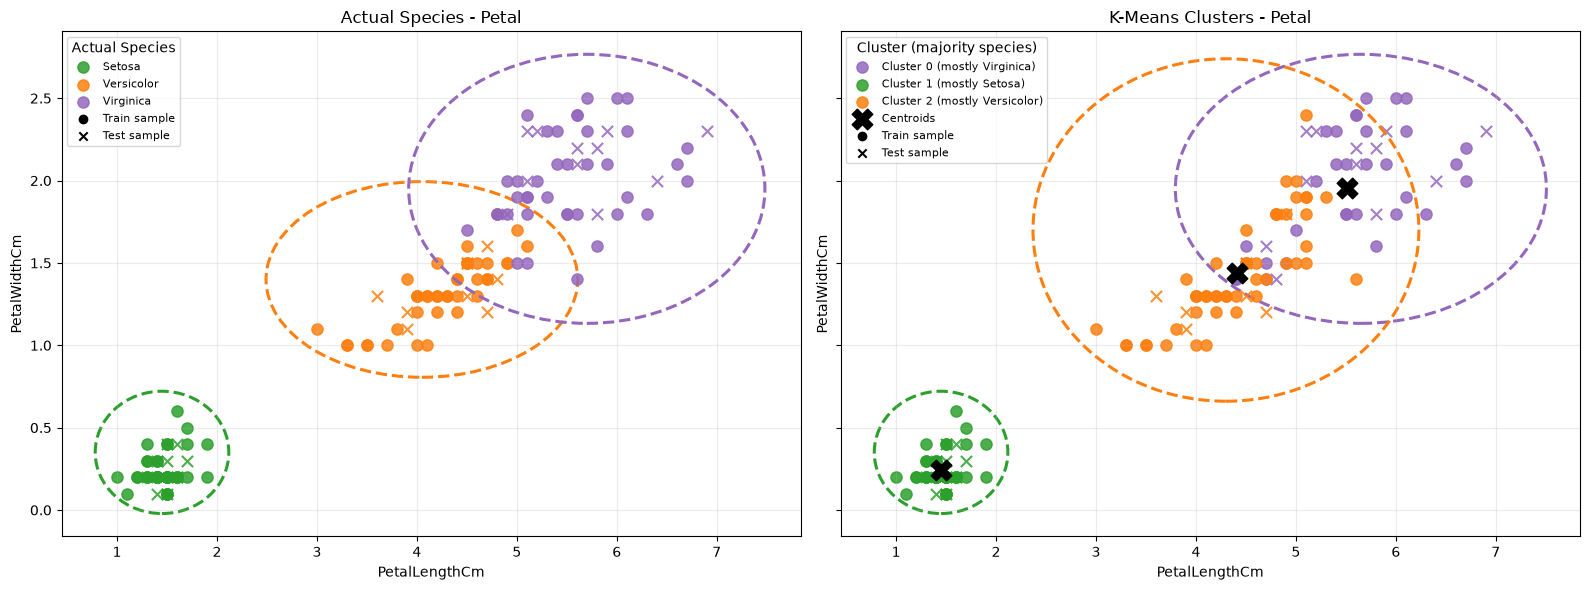

In [15]:
centers_original = kmeans_scaler.inverse_transform(kmeans.cluster_centers_)
compare_clusters('KMeans_Cluster', petal_pair, 'K-Means', centers_original, train_test=True)


### 8.1 K-Means - Sepal Comparison


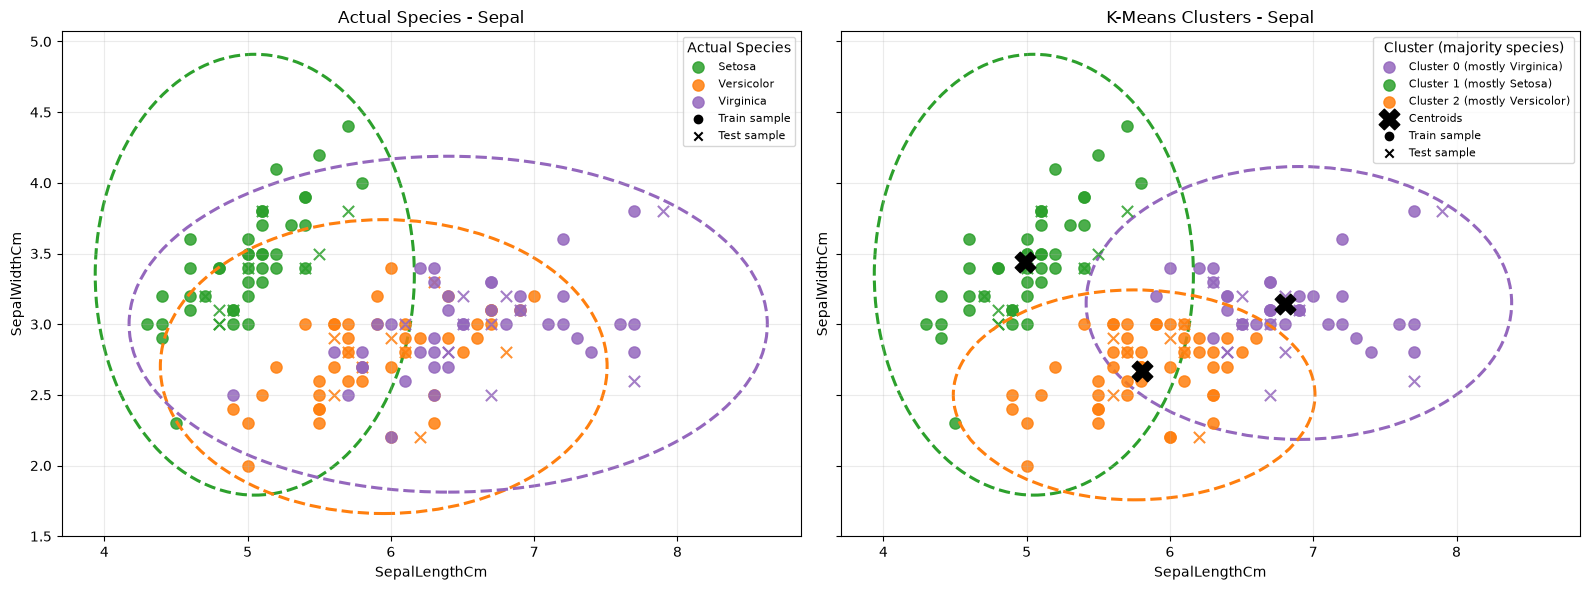

In [16]:
compare_clusters('KMeans_Cluster', sepal_pair, 'K-Means', centers_original, train_test=True)


## 9. K-Means Cluster Analysis

In [17]:
kmeans_summary = df.groupby('KMeans_Cluster')[feature_columns].mean()
display(kmeans_summary)

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
KMeans_Cluster,,,,
0,6.804444,3.106667,5.528889,1.977778
1,5.006000,3.418000,1.464000,0.244000
2,5.818182,2.680000,4.396364,1.429091


# Part B: Hierarchical Clustering
## 10. Create Linkage Matrix

In [18]:
linked = linkage(X_scaled, method='ward')

print("Linkage matrix created successfully.")
print("Linkage matrix shape:", linked.shape)

Linkage matrix created successfully.
Linkage matrix shape: (149, 4)


## 11. Actual Reference vs Agglomerative Dendrogram


,Cluster ID,Legend label,Flowers,Largest species share (%)
0,0,Cluster 0 (mostly Virginica),71,67.6
1,1,Cluster 1 (mostly Setosa),49,100.0
2,2,Cluster 2 (mostly Versicolor),30,90.0


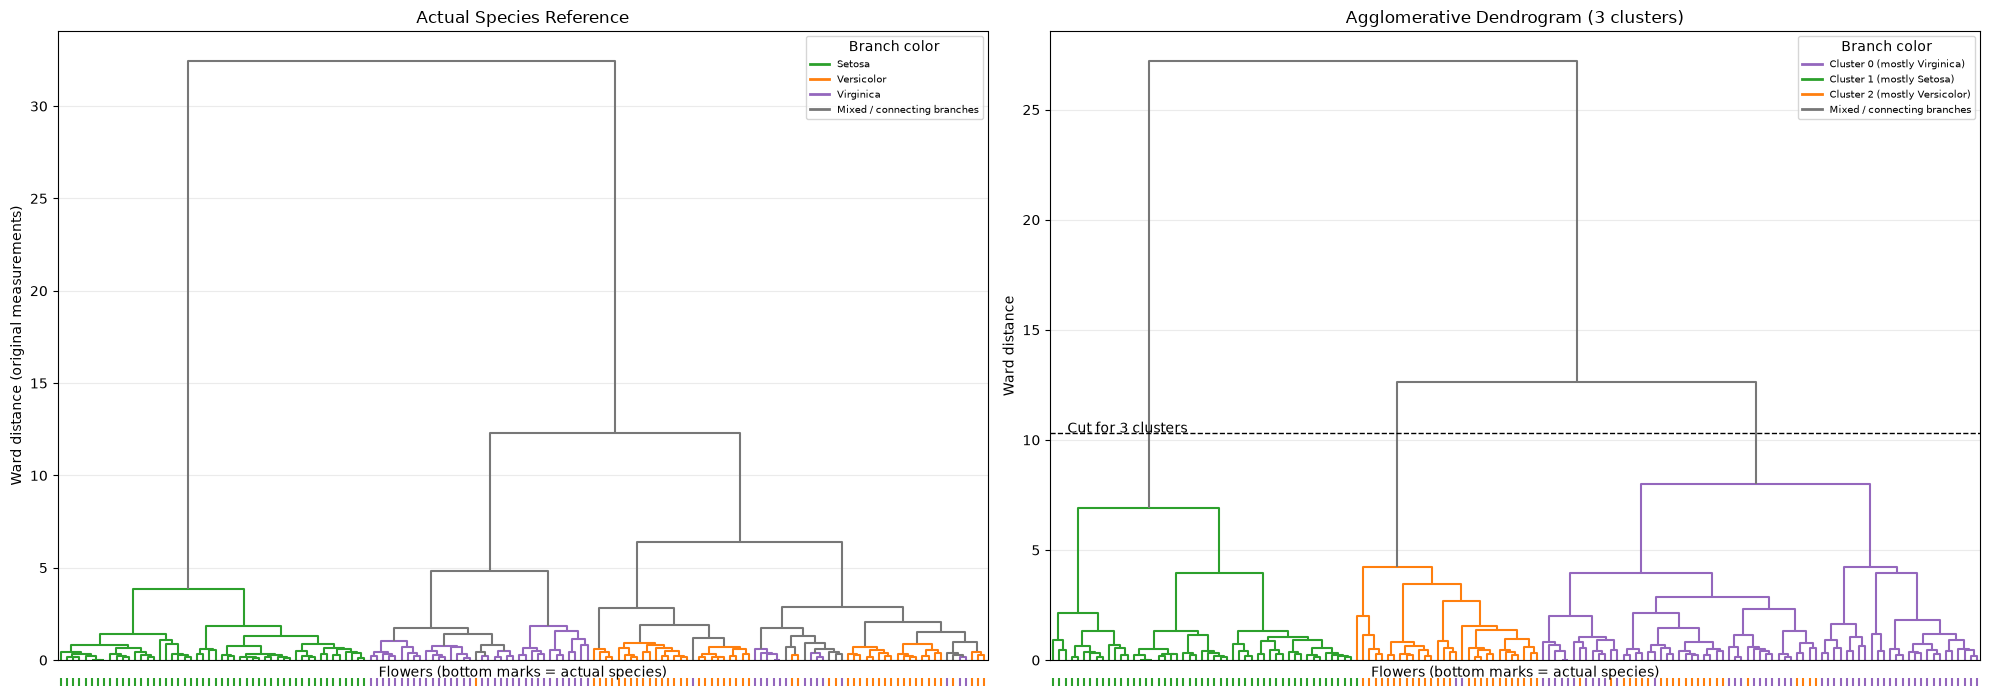

In [19]:
df['Hierarchical_Cluster'] = AgglomerativeClustering(
    n_clusters=3, linkage='ward'
).fit_predict(X_scaled)
hierarchical_cluster_labels = add_cluster_labels(df, 'Hierarchical_Cluster')

# Reference tree uses original measurements and actual species colors.
actual_linked = linkage(X.to_numpy(), method='ward')
fig, axes = plt.subplots(1, 2, figsize=(20, 7))
plot_colored_dendrogram(axes[0], actual_linked, 'Actual Species Reference',
                        ylabel='Ward distance (original measurements)')
plot_colored_dendrogram(axes[1], linked, 'Agglomerative Dendrogram (3 clusters)',
                        column='Hierarchical_Cluster')
cut_height = (linked[-3, 2] + linked[-2, 2]) / 2
axes[1].axhline(cut_height, color='black', linestyle='--', linewidth=1)
axes[1].text(0.01, cut_height, '  Cut for 3 clusters', transform=axes[1].get_yaxis_transform())
plt.tight_layout()
plt.show()


## 12. Determine Optimal Number of Clusters

In [20]:
print("Agglomerative Hierarchical Clustering completed.")
print(df['Hierarchical_Cluster'].value_counts().sort_index())

Agglomerative Hierarchical Clustering completed.
Hierarchical_Cluster
0    71
1    49
2    30
Name: count, dtype: int64


## 14. Hierarchical Cluster Analysis

In [21]:
hierarchical_summary = df.groupby('Hierarchical_Cluster')[feature_columns].mean()
display(hierarchical_summary)

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
Hierarchical_Cluster,,,,
0,6.546479,2.992958,5.267606,1.854930
1,5.016327,3.440816,1.467347,0.242857
2,5.530000,2.566667,3.930000,1.206667


# Part C: Divisive Hierarchical Clustering
## 15. Divisive Clustering and Recorded Split Hierarchy

In [22]:
def sse(indices):
    points = X_scaled[indices]
    return np.sum((points - points.mean(axis=0)) ** 2)

def make_group(indices):
    return {"indices": indices, "children": None, "height": np.sqrt(sse(indices))}

def split_group(group):
    indices = group["indices"]
    points = X_scaled[indices]
    if len(np.unique(points, axis=0)) == 1:
        middle = len(indices) // 2
        left, right = indices[:middle], indices[middle:]
    else:
        model = KMeans(n_clusters=2, random_state=RANDOM_STATE, n_init=10)
        labels = model.fit_predict(points)
        left, right = indices[labels == 0], indices[labels == 1]
    group["children"] = [make_group(left), make_group(right)]
    return group["children"]

root = make_group(np.arange(len(df)))
groups = [root]
while len(groups) < 3:
    # Split the most spread-out group that has at least two flowers.
    position = max((i for i in range(len(groups)) if len(groups[i]["indices"]) > 1),
                   key=lambda i: sse(groups[i]["indices"]))
    left, right = split_group(groups[position])
    groups[position] = left
    groups.append(right)

divisive_labels = np.zeros(len(df), dtype=int)
for cluster_id, group in enumerate(groups):
    divisive_labels[group["indices"]] = cluster_id
df["Divisive_Cluster"] = divisive_labels
print(df["Divisive_Cluster"].value_counts().sort_index())

divisive_cluster_labels = add_cluster_labels(df, 'Divisive_Cluster')
tree_rows = []

def build_tree(group):
    indices = group["indices"]
    if len(indices) == 1:
        return int(indices[0])
    if group["children"] is None:
        split_group(group)
    left = build_tree(group["children"][0])
    right = build_tree(group["children"][1])
    node_id = len(df) + len(tree_rows)
    tree_rows.append([left, right, group["height"], len(indices)])
    return node_id

build_tree(root)
divisive_linked = np.array(tree_rows)
assert is_valid_linkage(divisive_linked)

Divisive_Cluster
0    53
1    50
2    47
Name: count, dtype: int64


,Cluster ID,Legend label,Flowers,Largest species share (%)
0,0,Cluster 0 (mostly Versicolor),53,73.6
1,1,Cluster 1 (mostly Setosa),50,100.0
2,2,Cluster 2 (mostly Virginica),47,76.6


## 17. Divisive Cluster Analysis

In [23]:
divisive_summary = df.groupby('Divisive_Cluster')[feature_columns].mean()
display(divisive_summary)

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
Divisive_Cluster,,,,
0,5.801887,2.673585,4.369811,1.413208
1,5.006000,3.418000,1.464000,0.244000
2,6.780851,3.095745,5.510638,1.972340


## 18. Actual Reference vs Divisive Dendrogram


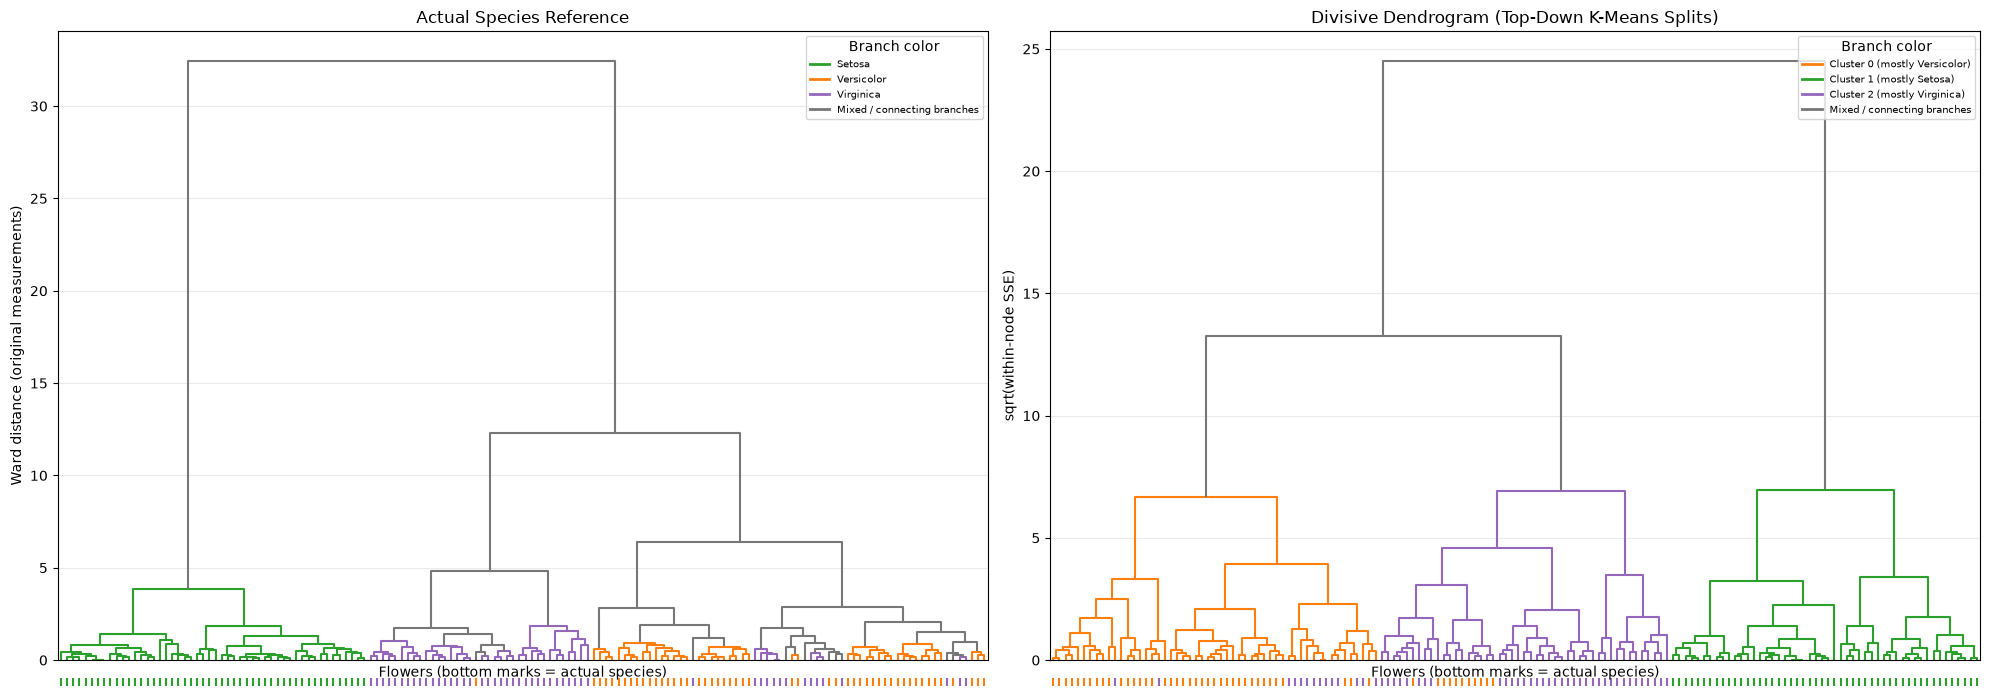

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(20, 7))
plot_colored_dendrogram(axes[0], actual_linked, 'Actual Species Reference',
                        ylabel='Ward distance (original measurements)')
plot_colored_dendrogram(axes[1], divisive_linked, 'Divisive Dendrogram (Top-Down K-Means Splits)',
                        column='Divisive_Cluster', ylabel='sqrt(within-node SSE)')
plt.tight_layout()
plt.show()


## 19. Actual Species Scatter Plot


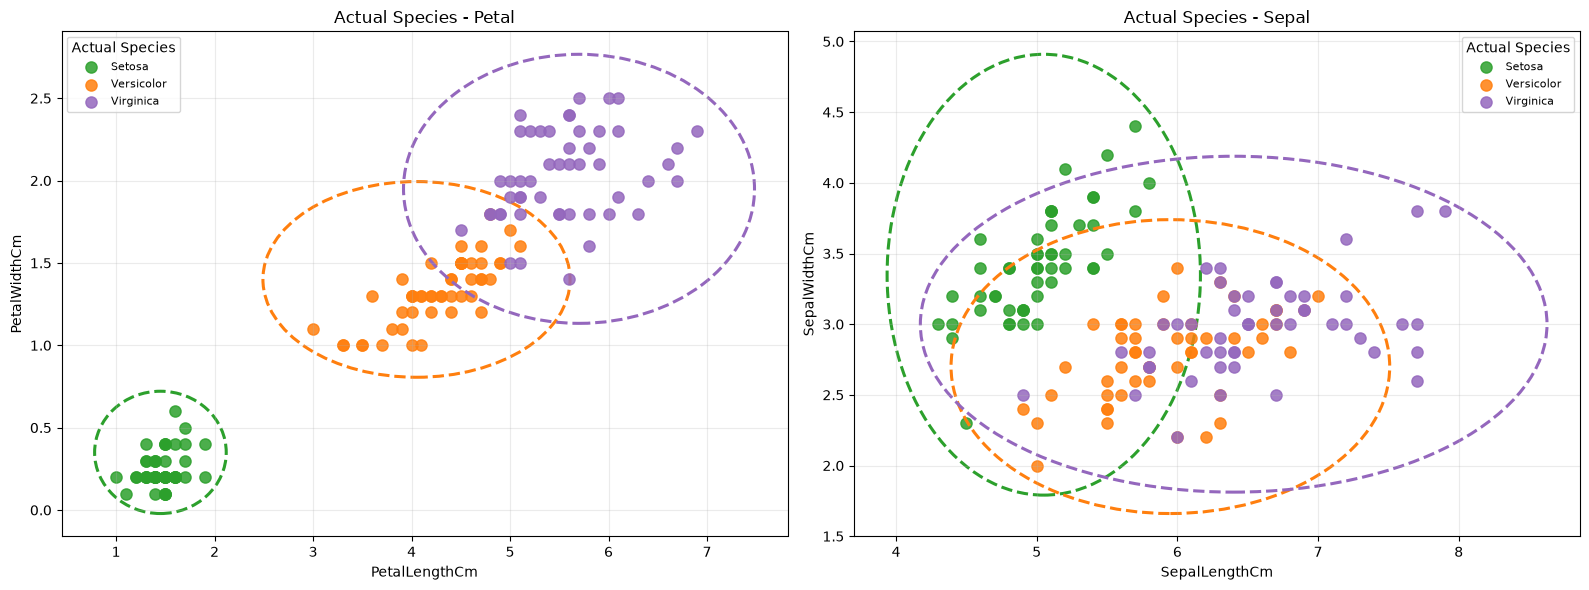

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
plot_feature_scatter(axes[0], 'Species', petal_pair, 'Actual Species - Petal')
plot_feature_scatter(axes[1], 'Species', sepal_pair, 'Actual Species - Sepal')
plt.tight_layout()
plt.show()


### 19.1 Dunn Index


In [26]:
def dunn_index(data, labels):
    data, labels = np.asarray(data), np.asarray(labels)
    clusters = np.unique(labels)
    if len(clusters) < 2:
        raise ValueError('Dunn Index needs at least two clusters.')
    distances = np.sqrt(((data[:, None] - data[None, :]) ** 2).sum(axis=2))
    max_within, min_between = 0.0, np.inf
    for i, cluster in enumerate(clusters):
        rows = np.where(labels == cluster)[0]
        max_within = max(max_within, distances[np.ix_(rows, rows)].max())
        for other in clusters[i + 1:]:
            other_rows = np.where(labels == other)[0]
            min_between = min(min_between, distances[np.ix_(rows, other_rows)].min())
    return min_between / max_within if max_within > 0 else np.inf


In [27]:
# Evaluate all three results in the same standardized four-feature space.
methods = {'K-Means': 'KMeans_Cluster', 'Agglomerative': 'Hierarchical_Cluster',
           'Divisive': 'Divisive_Cluster'}
dunn_rows = []
for method, column in methods.items():
    dunn_rows.append([method, df[column].nunique(), dunn_index(X_scaled, df[column])])
dunn_comparison = pd.DataFrame(dunn_rows, columns=['Method', 'Clusters', 'Dunn Index'])
display(dunn_comparison.round(4))
print('Higher Dunn Index is better.')


,Method,Clusters,Dunn Index
0,K-Means,3,0.0570
1,Agglomerative,3,0.0980
2,Divisive,3,0.0264


Higher Dunn Index is better.


## 21. Comparison Tables

In [28]:
print("Actual Species vs K-Means")
display(pd.crosstab(df['Species'], df['KMeans_Cluster_Label']))

print("Actual Species vs Agglomerative")
display(pd.crosstab(df['Species'], df['Hierarchical_Cluster_Label']))

print("Actual Species vs Divisive")
display(pd.crosstab(df['Species'], df['Divisive_Cluster_Label']))

Actual Species vs K-Means


KMeans_Cluster_Label,Cluster 0 (mostly Virginica),Cluster 1 (mostly Setosa),Cluster 2 (mostly Versicolor)
Species,,,
Iris-setosa,0,50,0
Iris-versicolor,11,0,39
Iris-virginica,34,0,16


Actual Species vs Agglomerative


Hierarchical_Cluster_Label,Cluster 0 (mostly Virginica),Cluster 1 (mostly Setosa),Cluster 2 (mostly Versicolor)
Species,,,
Iris-setosa,0,49,1
Iris-versicolor,23,0,27
Iris-virginica,48,0,2


Actual Species vs Divisive


Divisive_Cluster_Label,Cluster 0 (mostly Versicolor),Cluster 1 (mostly Setosa),Cluster 2 (mostly Virginica)
Species,,,
Iris-setosa,0,50,0
Iris-versicolor,39,0,11
Iris-virginica,14,0,36


## 22. Overall Comparison

| Method | Approach | Groups |
|---|---|---:|
| K-Means | Groups around centres | 3 |
| Agglomerative | Bottom-up Ward merges | 3 |
| Divisive | Top-down K-Means splits | 3 |